# RECOVER — Data Preprocessing

Here is an example image of the crate (from camera above) with the corresponding sensor layout:

<table>
  <tr>
    <td align="center">
      <img src="pig-camera-snapshot.png" alt="crate camera" width="500"><br>
      <em>Crate (camera view)</em>
    </td>
    <td align="center">
      <img src="piglet_sensor_loc.png" alt="sensor layout" width="500"><br>
      <em>Sensor layout</em>
    </td>
  </tr>
</table>

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


## 2. Load raw v2 data

In [2]:
# v2 data (grab from the shared google drive: v2 RECOVER folder)
# csv header: timestamp, sensor_id, reading_0, .... reading_499, activity_label

crate8 = pd.read_csv('v2_data/crate_08_4-28-2022.csv')
crate8_geophones = {"GEOSCOPE_SENSOR_20", "GEOSCOPE_SENSOR_21", "GEOSCOPE_SENSOR_22", "GEOSCOPE_SENSOR_23", "GEOSCOPE_SENSOR_24"}

crate9 = pd.read_csv('v2_data/crate_09_4-29-2022.csv')
crate9_geophones = {"GEOSCOPE_SENSOR_10", "GEOSCOPE_SENSOR_11", "GEOSCOPE_SENSOR_12", "GEOSCOPE_SENSOR_13", "GEOSCOPE_SENSOR_14"}



In [3]:
crate8.head()

,timestamp,sensor_id,reading_0,reading_1,reading_2,reading_3,reading_4,reading_5,reading_6,reading_7,...,reading_491,reading_492,reading_493,reading_494,reading_495,reading_496,reading_497,reading_498,reading_499,activity_label
0,2022-04-28 00:00:00-05:00,GEOSCOPE_SENSOR_20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lying
1,2022-04-28 00:00:00-05:00,GEOSCOPE_SENSOR_21,2054.0,2053.0,2054.0,2054.0,2054.0,2053.0,2056.0,2055.0,...,2057.0,2056.0,2057.0,2055.0,2055.0,2055.0,2054.0,2054.0,2054.0,lying
2,2022-04-28 00:00:00-05:00,GEOSCOPE_SENSOR_22,2060.0,2057.0,2057.0,2056.0,2056.0,2056.0,2057.0,2057.0,...,2058.0,2057.0,2056.0,2056.0,2056.0,2057.0,2059.0,2060.0,2060.0,lying
3,2022-04-28 00:00:00-05:00,GEOSCOPE_SENSOR_23,2050.0,2055.0,2053.0,2053.0,2054.0,2053.0,2054.0,2053.0,...,2057.0,2057.0,2058.0,2056.0,2055.0,2056.0,2053.0,2054.0,2053.0,lying
4,2022-04-28 00:00:00-05:00,GEOSCOPE_SENSOR_24,2056.0,2055.0,2056.0,2058.0,2059.0,2061.0,2061.0,2061.0,...,2058.0,2057.0,2058.0,2059.0,2058.0,2058.0,2057.0,2056.0,2056.0,lying


## 3. EDA — activity labels & signal inspection

['sitting', 'drinking+sitting', 'standing', 'eating+standing', 'drinking+standing']
{'sitting': 78668.0, 'drinking+sitting': 65286.0, 'standing': 64889.0, 'eating+standing': 9700.0, 'drinking+standing': 3724.0}


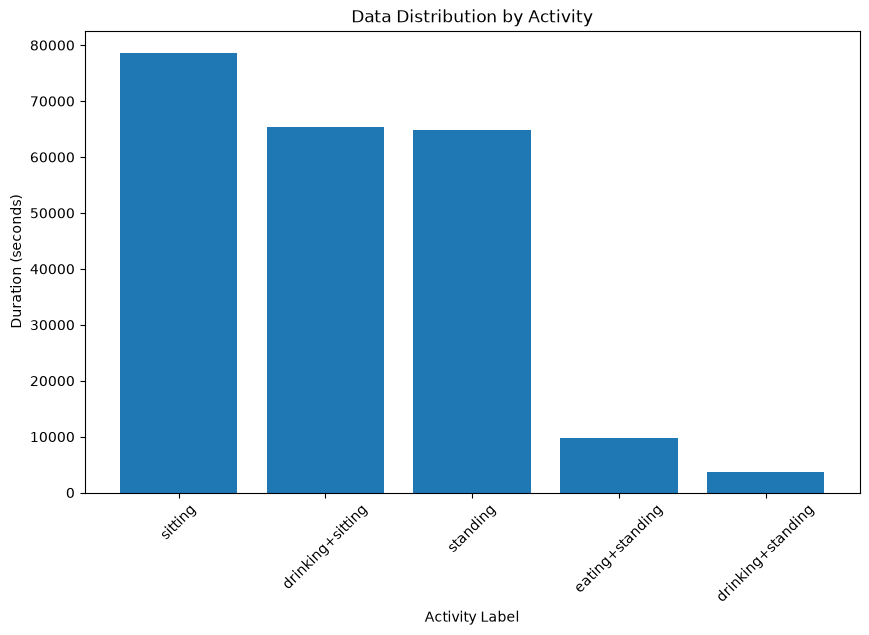

In [4]:
# mimic jeongmin's approach: subsets based on activity label + vizualize the different labels (& at various durations)
# jeongmin classes: drinking, eating, sitting, standing 

labels = crate8['activity_label'].unique() # data annotations: ['lying' 'Idle' 'sitting' 'drinking+sitting' 'standing' 'eating+standing' 'drinking+standing' nan]

# dropping nan, Idle, and Lying labels, since we want activities that have vibration data associated with them

# lei: should we keep the lying class? I will leave that up to you...
labels = [label for label in labels if pd.notna(label) and label != 'Idle' and label != 'lying']
print(labels) # ['sitting', 'drinking+sitting', 'standing', 'eating+standing', 'drinking+standing']

# getting the average duration for each activity label in crate8
activity_durations = {}
for label in labels:
    if pd.isna(label):
        continue
    label_data = crate8[crate8['activity_label'] == label]
    timestamps = pd.to_datetime(
        label_data["timestamp"],
        errors="coerce",
        utc=True,
    ).dropna()

    if timestamps.empty:
        duration = 0.0
    else:
        duration = (
            timestamps.max() - timestamps.min()
        ).total_seconds()
    activity_durations[label] = duration

print(activity_durations) # {'sitting': 78668.0, 'drinking+sitting': 65286.0, 'standing': 64889.0, 'eating+standing': 9700.0, 'drinking+standing': 3724.0}

# visualize data distribution for each activity label in crate8
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(activity_durations.keys(), activity_durations.values())
plt.xlabel('Activity Label')
plt.ylabel('Duration (seconds)')
plt.title('Data Distribution by Activity')
plt.xticks(rotation=45)
plt.show()


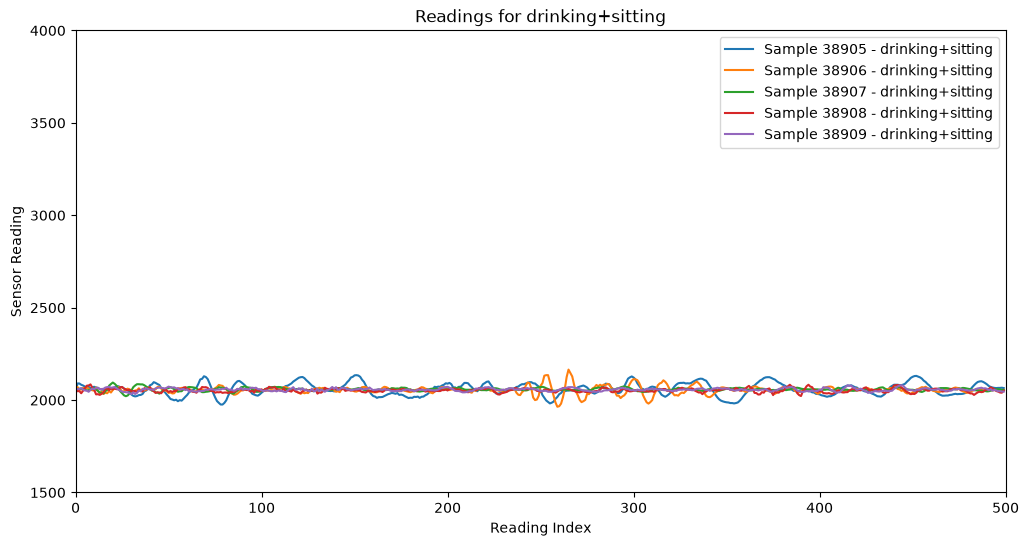

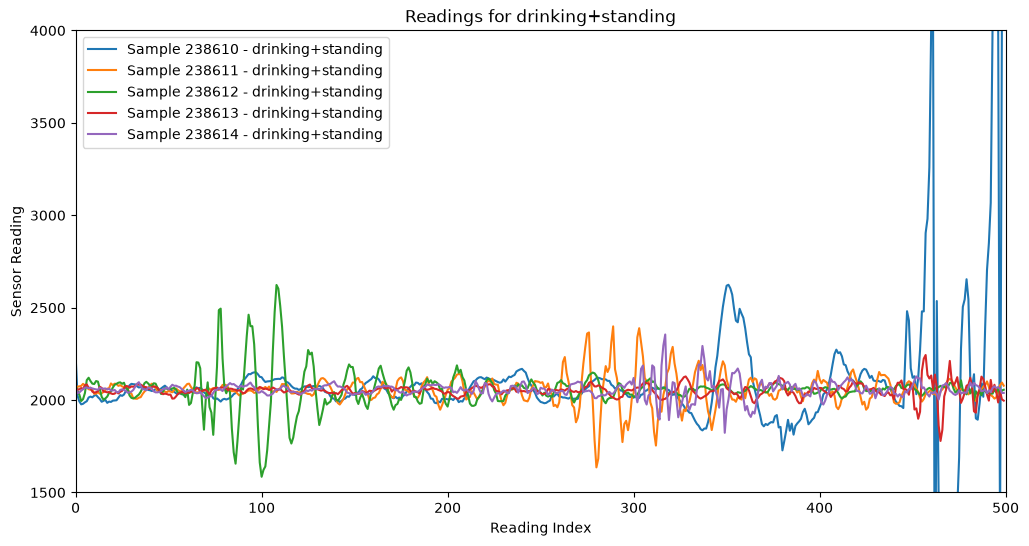

In [5]:
# comparing how some example signals look for drinking+sitting vs. drinking+standing

for label in labels:
    if label in ['drinking+sitting', 'drinking+standing']:
        label_data = crate8[crate8['activity_label'] == label]
        timestamps = pd.to_datetime(
            label_data["timestamp"],
            errors="coerce",
            utc=True,
        ).dropna()

        if timestamps.empty:
            continue

        # Get the first 5 rows of data for this label (one row per sensor - 5 sensors)
        sample_data = label_data.head(5)

        reading_cols = [c for c in crate8.columns if c.startswith('reading_')]
        # Plot the readings for each sample
        plt.figure(figsize=(12, 6))
        for index, row in sample_data.iterrows():
            plt.plot(row[reading_cols].values, label=f'Sample {index} - {label}')
        
        plt.title(f'Readings for {label}')
        plt.xlabel('Reading Index')
        plt.ylabel('Sensor Reading')
        # want the same axis to compare
        plt.ylim(1500, 4000) 
        plt.xlim(0, 500)
        plt.legend()
        plt.show()

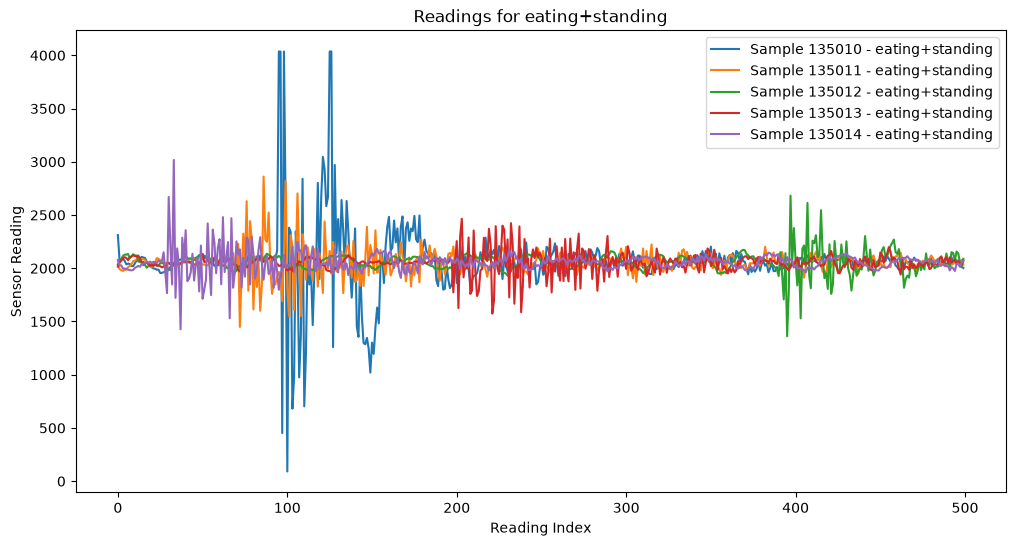

In [6]:
# looking at the eating signals

for label in labels:
    if label in ['eating+standing']:
        label_data = crate8[crate8['activity_label'] == label]
        timestamps = pd.to_datetime(
            label_data["timestamp"],
            errors="coerce",
            utc=True,
        ).dropna()

        if timestamps.empty:
            continue

        # Get the first 5 rows of data for this label
        sample_data = label_data.head(5)
        rows = sample_data.shape[0]

        reading_cols = [c for c in crate8.columns if c.startswith('reading_')]
        # Plot the readings for each sample
        plt.figure(figsize=(12, 6))
        for index, row in sample_data.iterrows():
            plt.plot(row[reading_cols].values, label=f'Sample {index} - {label}')
        
        plt.title(f'Readings for {label}')
        plt.xlabel('Reading Index')
        plt.ylabel('Sensor Reading')
        plt.legend()
        plt.show()

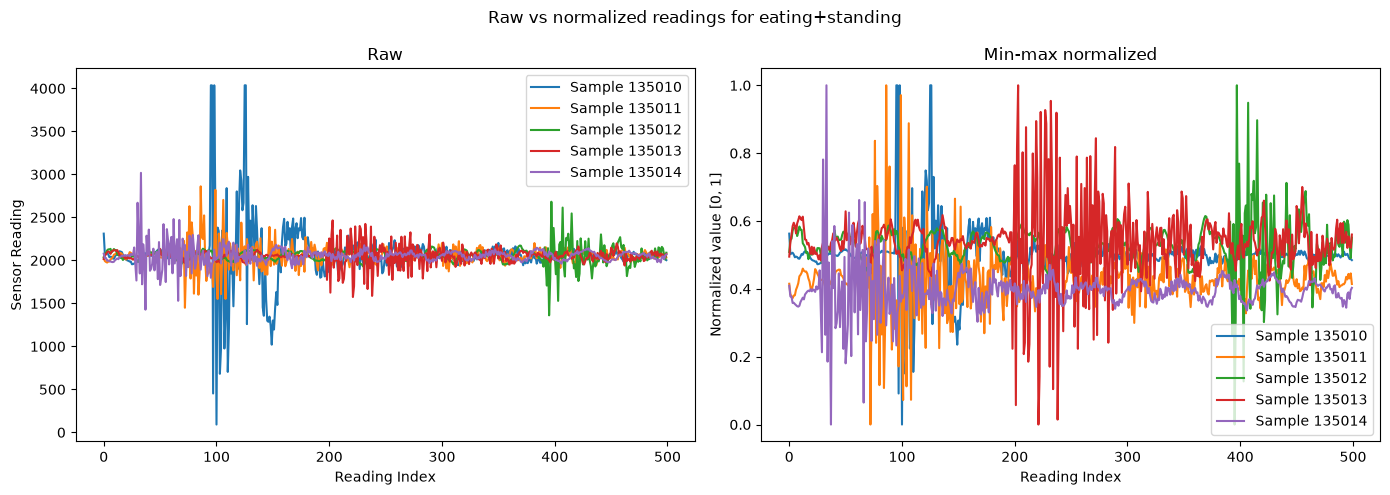

In [7]:
# taking the eating_standing example, normalizing, and comparing to raw signal plot

for label in labels:
    if label in ['eating+standing']:
        label_data = crate8[crate8['activity_label'] == label]
        timestamps = pd.to_datetime(
            label_data["timestamp"],
            errors="coerce",
            utc=True,
        ).dropna()

        if timestamps.empty:
            continue

        # Get the first 5 rows of data for this label
        sample_data = label_data.head(5)
        reading_cols = [c for c in crate8.columns if c.startswith('reading_')]
        # Plot raw and normalized readings for each sample
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f'Raw vs normalized readings for {label}')
        for index, row in sample_data.iterrows():
            readings = row[reading_cols].values.astype(float)
            lo, hi = readings.min(), readings.max()
            normalized_readings = (readings - lo) / (hi - lo + 1e-9)
            axes[0].plot(readings, label=f'Sample {index}')
            axes[1].plot(normalized_readings, label=f'Sample {index}')
        axes[0].set_title('Raw'); axes[0].set_xlabel('Reading Index'); axes[0].set_ylabel('Sensor Reading')
        axes[1].set_title('Min-max normalized'); axes[1].set_xlabel('Reading Index'); axes[1].set_ylabel('Normalized value [0, 1]')
        axes[0].legend(); axes[1].legend()
        
        plt.tight_layout()
        plt.show()

## 4. Build v2 subset CSVs
Outputs to `v2_data/subsets/` — run this to regenerate the CSVs.

In [8]:
# old recover data subsets: ()
eating = pd.read_csv("jeongmin_data/eating_1000.csv")
eating.head()
# 5 rows (one per sensor)
DATA_FILES = {
    "eating":   pd.read_csv("jeongmin_data/eating_1000.csv", header=None),
    "drinking": pd.read_csv("jeongmin_data/drinking_1000.csv", header=None),
    "sitting":  pd.read_csv("jeongmin_data/sitting_1000.csv",  header=None),
    "standing": pd.read_csv("jeongmin_data/standing_1000.csv", header=None),
}


N_SAMPLES_PER_CLASS = 6000
WINDOW_LENGTH = 100
SENSOR_NUM = 5

In [9]:
# ── Build v2 subset CSVs in Jeongmin's format ─────────────────────────────────
#

# lei -- double check this is correct and how you want this to be done!!

# Format matches Jeongmin's *_1000.csv files:
#   - Each row = 1000 columns (2 consecutive 500-sample rows = 2 s @ 500 Hz)
#   - Rows grouped in chunks of SENSOR_NUM (one per sensor, same time window)
#   - Values min-max normalized to [0, 1] per sensor using that sensor's global range
#
# Both crates are used (sensors 20-24 from crate8, 10-14 from crate9).
# Label mapping: eating+standing->eating, drinking+sitting/standing->drinking.

import numpy as np
import pandas as pd
from pathlib import Path

LABEL_MAP = {
    "eating+standing":   "eating",
    "drinking+sitting":  "drinking",
    "drinking+standing": "drinking",
    "sitting":           "sitting",
    "standing":          "standing",
    "lying":             "lying", # do we want to keep this class? I will leave that up to you...
}
CLASSES = ["eating", "drinking", "sitting", "standing"]
reading_cols = [c for c in crate8.columns if c.startswith("reading_")]

def prep(df):
    df = df.copy()
    df["timestamp"]    = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
    df["mapped_label"] = df["activity_label"].map(LABEL_MAP)
    return df[df["mapped_label"].notna()].copy()

c8 = prep(crate8)
c9 = prep(crate9)

# Per-sensor global min/max across all labeled data (each sensor has a unique ID)
all_labeled = pd.concat([c8, c9], ignore_index=True)
sensor_stats = {
    s: (float(grp[reading_cols].values.ravel().astype(float)[
            ~np.isnan(grp[reading_cols].values.ravel().astype(float))].min()),
        float(grp[reading_cols].values.ravel().astype(float)[
            ~np.isnan(grp[reading_cols].values.ravel().astype(float))].max()))
    for s, grp in all_labeled.groupby("sensor_id")
}

def minmax(arr, lo, hi):
    a = arr.astype(float)
    normed = (a - lo) / (hi - lo + 1e-9)
    # fill any NaN readings with 0.5 (mid-range after normalization)
    normed = np.where(np.isnan(normed), 0.5, normed)
    return normed

def extract_windows(cls_df, sensors):
    """Non-overlapping 2-s windows within contiguous bouts; 5 rows per window."""
    crate_cls = cls_df[cls_df["sensor_id"].isin(sensors)]

    # Timestamps where all sensors are present (keep as tz-aware pandas Index)
    ts_ok = (
        crate_cls.groupby("timestamp")["sensor_id"].nunique()
        .pipe(lambda s: s[s == len(sensors)])
        .index.sort_values()
    )

    # Precompute dict (timestamp, sensor_id) -> reading array for fast lookup
    sub = crate_cls[crate_cls["timestamp"].isin(ts_ok)]
    lookup = {(r[0], r[1]): r[2]
              for r in zip(sub["timestamp"], sub["sensor_id"],
                           list(sub[reading_cols].values))}

    rows = []
    ts_list = list(ts_ok)          # keep as tz-aware Timestamps
    i = 0
    while i < len(ts_list) - 1:
        gap = (ts_list[i + 1] - ts_list[i]).total_seconds()
        if abs(gap - 1.0) < 0.1:
            t0, t1 = ts_list[i], ts_list[i + 1]
            for s in sensors:
                r0 = lookup.get((t0, s))
                r1 = lookup.get((t1, s))
                if r0 is not None and r1 is not None:
                    rows.append(minmax(np.concatenate([r0, r1]), *sensor_stats[s]))
            i += 2
        else:
            i += 1
    return rows

out_dir = Path("v2_data/subsets")
out_dir.mkdir(exist_ok=True)

c8_sensors = sorted(c8["sensor_id"].unique())
c9_sensors = sorted(c9["sensor_id"].unique())

print(f"{'Class':<12} {'crate8 rows':>12} {'crate9 rows':>12} {'total rows':>12}")
print("-" * 52)
for cls in CLASSES:
    rows = []
    for crate_df, sensors in [(c8, c8_sensors), (c9, c9_sensors)]:
        rows += extract_windows(crate_df[crate_df["mapped_label"] == cls], sensors)

    arr = np.array(rows)
    path = out_dir / f"{cls}_1000.csv"
    np.savetxt(path, arr, delimiter=",")

    r8 = len(extract_windows(c8[c8["mapped_label"] == cls], c8_sensors))
    r9 = len(rows) - r8
    print(f"{cls:<12} {r8:>12} {r9:>12} {len(rows):>12}")

print()

# Update DATA_FILES and N_SAMPLES_PER_CLASS for the rest of the notebook
DATA_FILES = {
    cls: pd.read_csv(out_dir / f"{cls}_1000.csv", header=None)
    for cls in CLASSES
}
N_SAMPLES_PER_CLASS = min(df.shape[0] for df in DATA_FILES.values())
N_SAMPLES_PER_CLASS = (N_SAMPLES_PER_CLASS // SENSOR_NUM) * SENSOR_NUM
print(f"DATA_FILES updated to v2 subsets.")
print(f"N_SAMPLES_PER_CLASS set to {N_SAMPLES_PER_CLASS} (bottleneck: drinking)")


Class         crate8 rows  crate9 rows   total rows
----------------------------------------------------
eating               6510         7870        14380
drinking             2135         3800         5935
sitting             16105        11140        27245
standing             8575        26450        35025

DATA_FILES updated to v2 subsets.
N_SAMPLES_PER_CLASS set to 5935 (bottleneck: drinking)


## 6. Visualize output

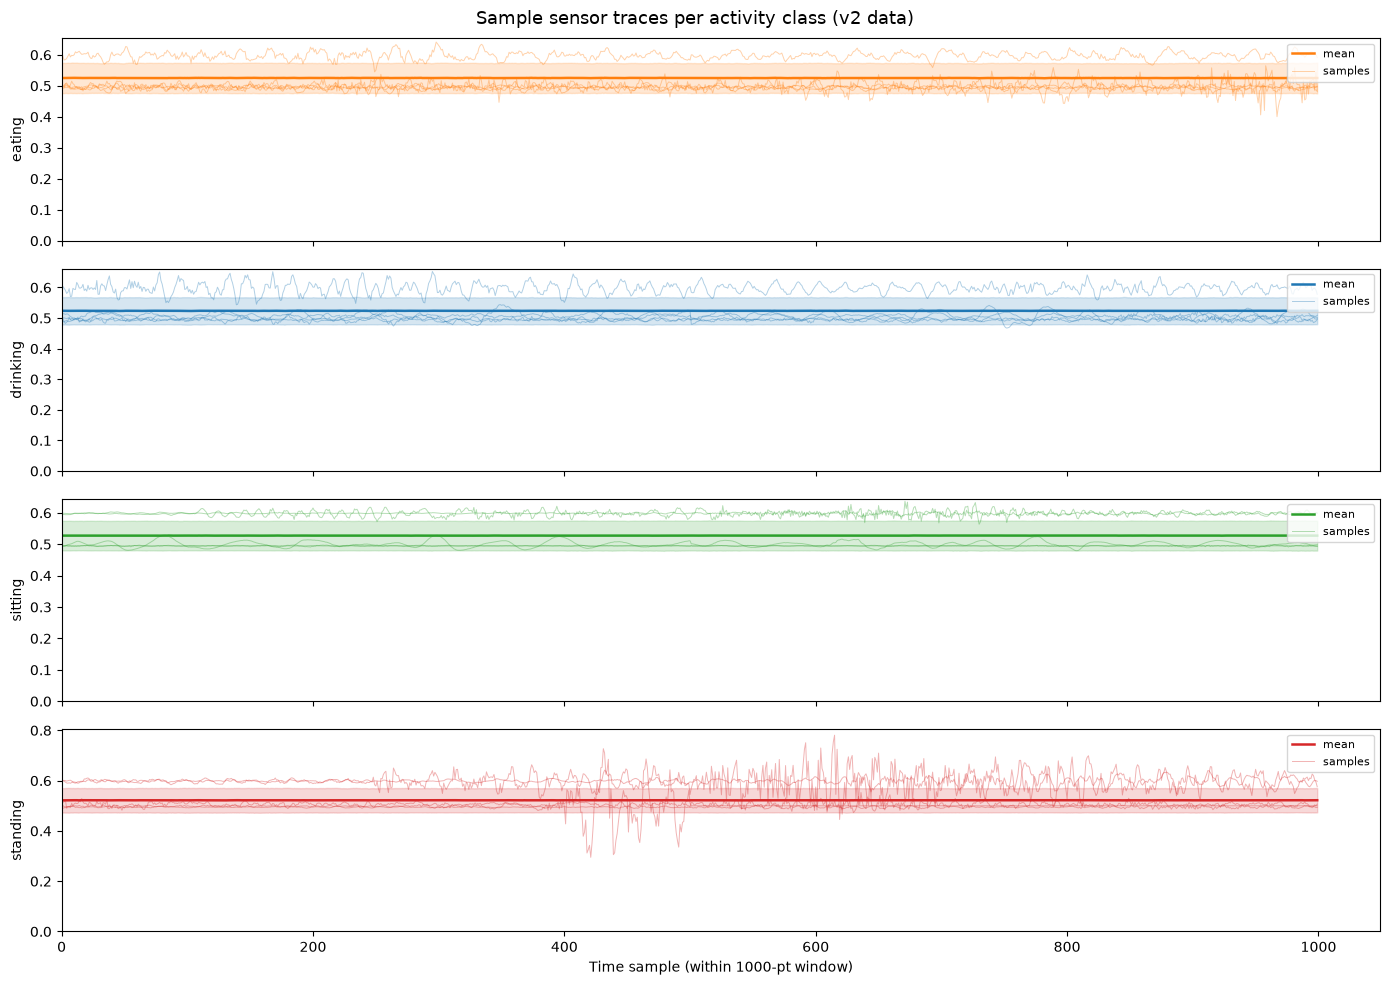

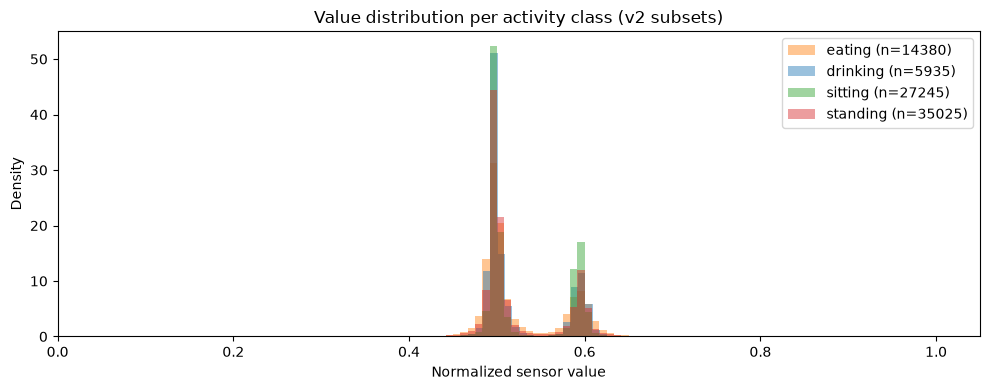

Activity        rows    mean     std      min      max      <0      >1
--------------------------------------------------------------
eating         14380  0.5252  0.0484   0.0000   1.0000       0       0
drinking        5935  0.5237  0.0442   0.0017   1.0000       0       0
sitting        27245  0.5275  0.0473   0.0000   1.0000       0       0
standing       35025  0.5219  0.0483   0.0000   1.0000       0       0

Jeongmin reference:
Activity          min      max      <0      >1
--------------------------------------------
eating        -0.0582   1.0021      72     109
drinking      -0.0015   1.0024       9     132
sitting       -0.1448   1.0060      92     147
standing      -0.0017   1.0015      11      59


In [11]:
# ── Visualize v2 subset CSVs (compare structure to Jeongmin's data) ───────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

v2 = {
    cls: pd.read_csv(Path("v2_data/subsets") / f"{cls}_1000.csv", header=None).values
    for cls in ["eating", "drinking", "sitting", "standing"]
}

ACTIVITIES = list(v2.keys())
COLORS = {"eating": "tab:orange", "drinking": "tab:blue",
          "sitting": "tab:green",  "standing": "tab:red"}
rng = np.random.default_rng(0)

# ── Sample traces per class ───────────────────────────────────────────────────
fig, axes = plt.subplots(len(ACTIVITIES), 1, figsize=(14, 10), sharex=True)
fig.suptitle("Sample sensor traces per activity class (v2 data)", fontsize=13)

for ax, act in zip(axes, ACTIVITIES):
    data = v2[act]
    t    = np.arange(data.shape[1])
    mean = data.mean(axis=0)
    std  = data.std(axis=0)
    color = COLORS[act]
    ax.fill_between(t, mean - std, mean + std, alpha=0.18, color=color)
    ax.plot(t, mean, color=color, lw=1.8, label="mean")
    idx = rng.choice(len(data), size=min(5, len(data)), replace=False)
    for i, row in enumerate(data[idx]):
        ax.plot(t, row, color=color, alpha=0.35, lw=0.7,
                label="samples" if i == 0 else None)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.set_ylabel(act, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("Time sample (within 1000-pt window)")
plt.tight_layout()
plt.show()

# ── Value distribution per class ──────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(10, 4))
for act in ACTIVITIES:
    ax2.hist(v2[act].ravel(), bins=120, alpha=0.45, color=COLORS[act],
             label=f"{act} (n={len(v2[act])})", density=True)
ax2.set_xlim(left=0)
ax2.set_ylim(bottom=0)
ax2.set_xlabel("Normalized sensor value")
ax2.set_ylabel("Density")
ax2.set_title("Value distribution per activity class (v2 subsets)")
ax2.legend()
plt.tight_layout()
plt.show()

# ── Summary stats ─────────────────────────────────────────────────────────────
print(f"{'Activity':<12} {'rows':>7} {'mean':>7} {'std':>7} {'min':>8} {'max':>8}  {'<0':>6}  {'>1':>6}")
print("-" * 62)
for act, data in v2.items():
    print(f"{act:<12} {data.shape[0]:>7} {data.mean():>7.4f} {data.std():>7.4f} "
          f"{data.min():>8.4f} {data.max():>8.4f}  {(data<0).sum():>6}  {(data>1).sum():>6}")

print()
print("Jeongmin reference:")
print(f"{'Activity':<12} {'min':>8} {'max':>8}  {'<0':>6}  {'>1':>6}")
print("-" * 44)
for act in ACTIVITIES:
    j = pd.read_csv(f"jeongmin_data/{act}_1000.csv", header=None).values
    print(f"{act:<12} {j.min():>8.4f} {j.max():>8.4f}  {(j<0).sum():>6}  {(j>1).sum():>6}")


## 7. Compare v2 subsets vs Jeongmin's data

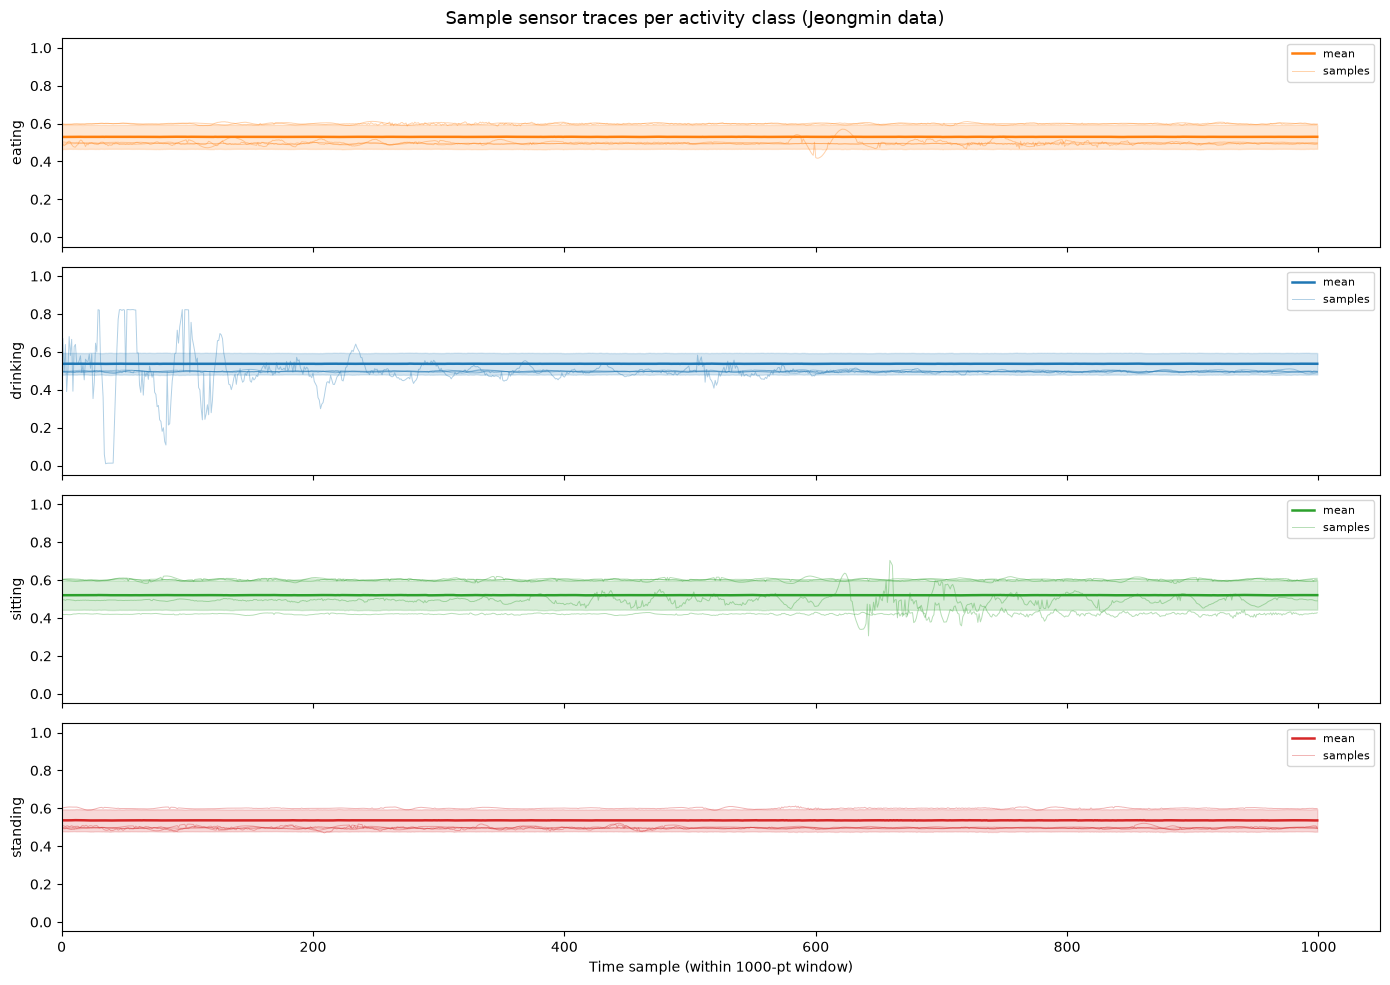

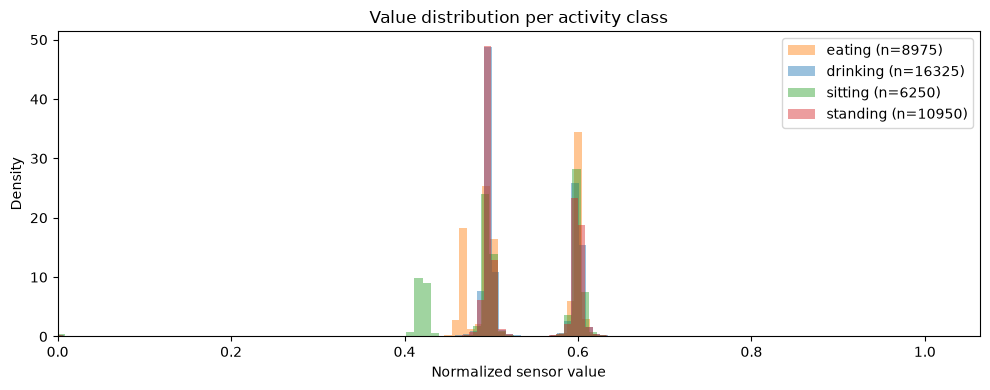

Activity        rows    mean     std     min     max
------------------------------------------------
eating          8975  0.5300  0.0637 -0.0582  1.0021
drinking       16325  0.5370  0.0571 -0.0015  1.0024
sitting         6250  0.5204  0.0773 -0.1448  1.0060
standing       10950  0.5367  0.0587 -0.0017  1.0015


In [14]:
# ── Visualize Jeongmin's activity CSVs ─────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

jeongmin = {
    "eating":    pd.read_csv("jeongmin_data/eating_1000.csv",   header=None).values,
    "drinking":  pd.read_csv("jeongmin_data/drinking_1000.csv", header=None).values,
    "sitting":   pd.read_csv("jeongmin_data/sitting_1000.csv",  header=None).values,
    "standing":  pd.read_csv("jeongmin_data/standing_1000.csv", header=None).values,
}

ACTIVITIES = list(jeongmin.keys())
COLORS = {"eating": "tab:orange", "drinking": "tab:blue",
          "sitting": "tab:green",  "standing": "tab:red"}
N_SAMPLE_TRACES = 5
rng = np.random.default_rng(0)

fig, axes = plt.subplots(len(ACTIVITIES), 1, figsize=(14, 10), sharex=True)
fig.suptitle("Sample sensor traces per activity class (Jeongmin data)", fontsize=13)

for ax, act in zip(axes, ACTIVITIES):
    data = jeongmin[act]           # shape (n_windows, 1000)
    t = np.arange(data.shape[1])
    mean = data.mean(axis=0)
    std  = data.std(axis=0)
    color = COLORS[act]

    # mean ± 1 std envelope
    ax.fill_between(t, mean - std, mean + std, alpha=0.18, color=color)
    ax.plot(t, mean, color=color, lw=1.8, label="mean")

    # a few individual traces
    idx = rng.choice(len(data), size=min(N_SAMPLE_TRACES, len(data)), replace=False)
    for i, row in enumerate(data[idx]):
        ax.plot(t, row, color=color, alpha=0.35, lw=0.7,
                label="samples" if i == 0 else None)

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.set_ylabel(act, fontsize=10)
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("Time sample (within 1000-pt window)")
plt.tight_layout()
plt.show()

# ── Value distribution per class ───────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(10, 4))
for act in ACTIVITIES:
    flat = jeongmin[act].ravel()
    ax2.hist(flat, bins=120, alpha=0.45, color=COLORS[act],
             label=f"{act} (n={len(jeongmin[act])})", density=True)
ax2.set_xlim(left=0)
ax2.set_ylim(bottom=0)
ax2.set_xlabel("Normalized sensor value")
ax2.set_ylabel("Density")
ax2.set_title("Value distribution per activity class")
ax2.legend()
plt.tight_layout()
plt.show()

# ── Summary stats ──────────────────────────────────────────────────────────────
print(f"{'Activity':<12} {'rows':>7} {'mean':>7} {'std':>7} {'min':>7} {'max':>7}")
print("-" * 48)
for act, data in jeongmin.items():
    print(f"{act:<12} {data.shape[0]:>7} {data.mean():>7.4f} "
          f"{data.std():>7.4f} {data.min():>7.4f} {data.max():>7.4f}")


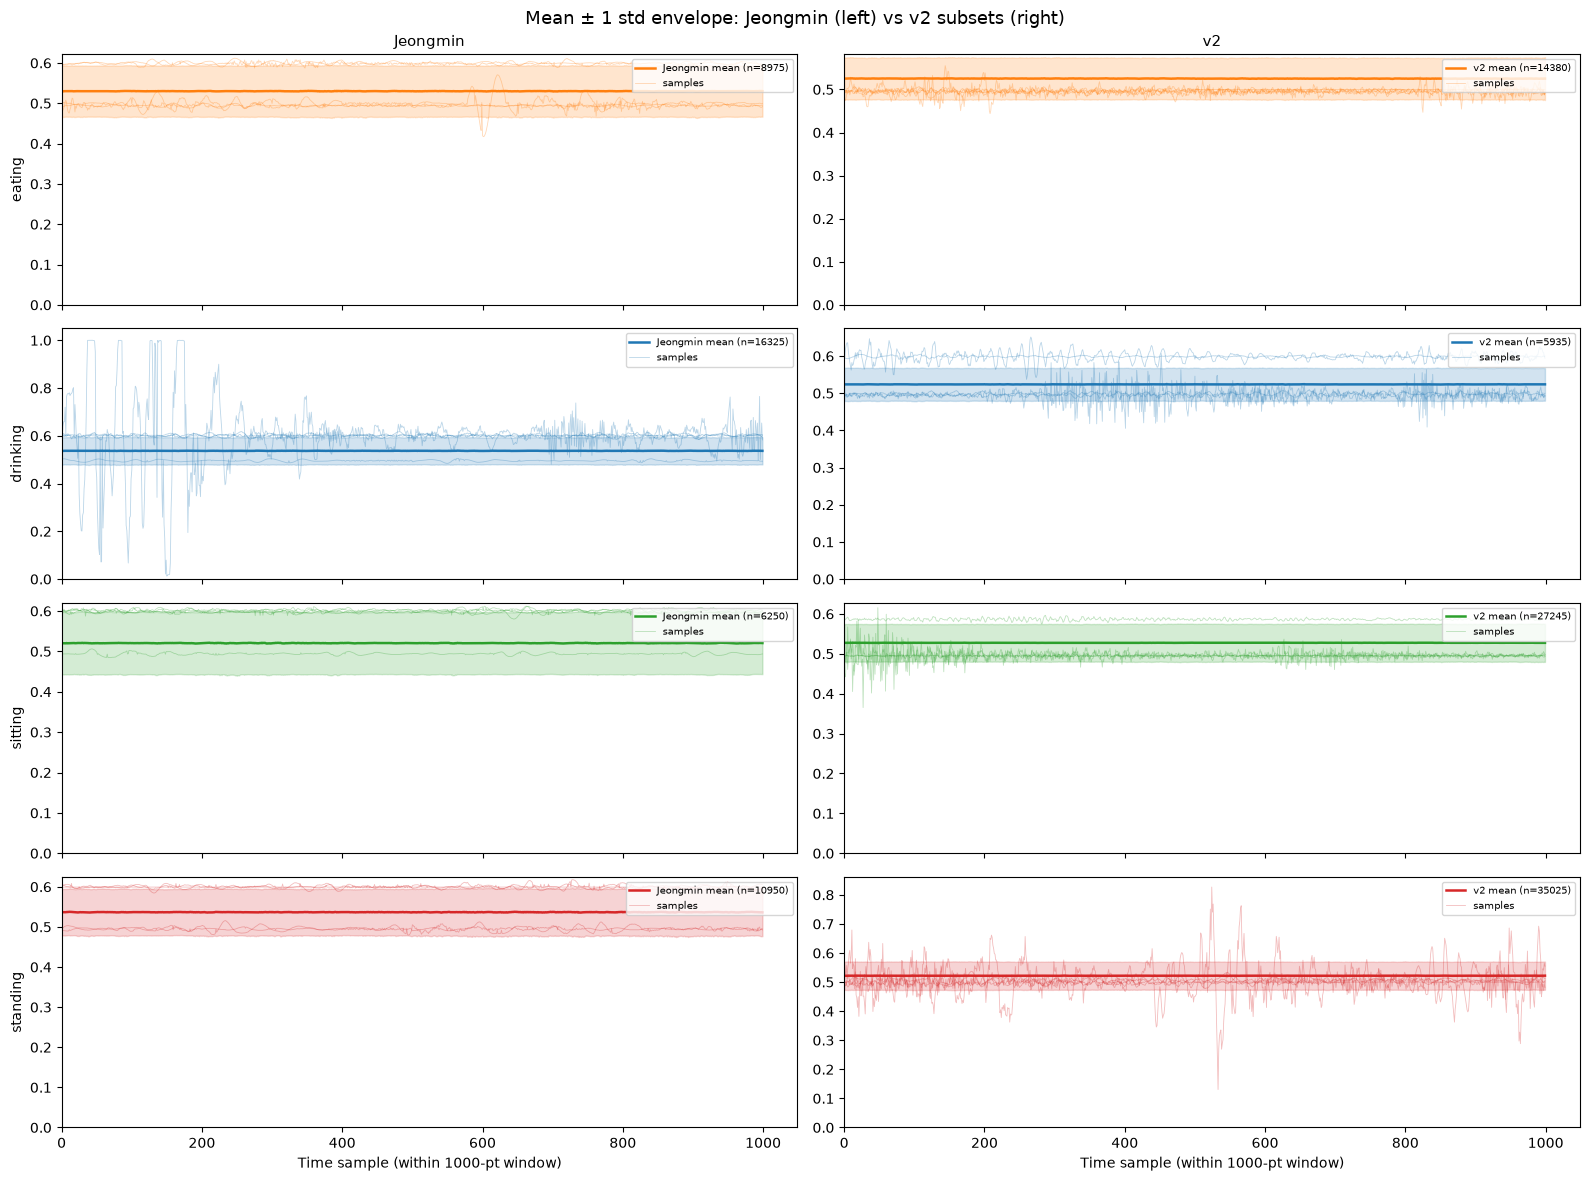

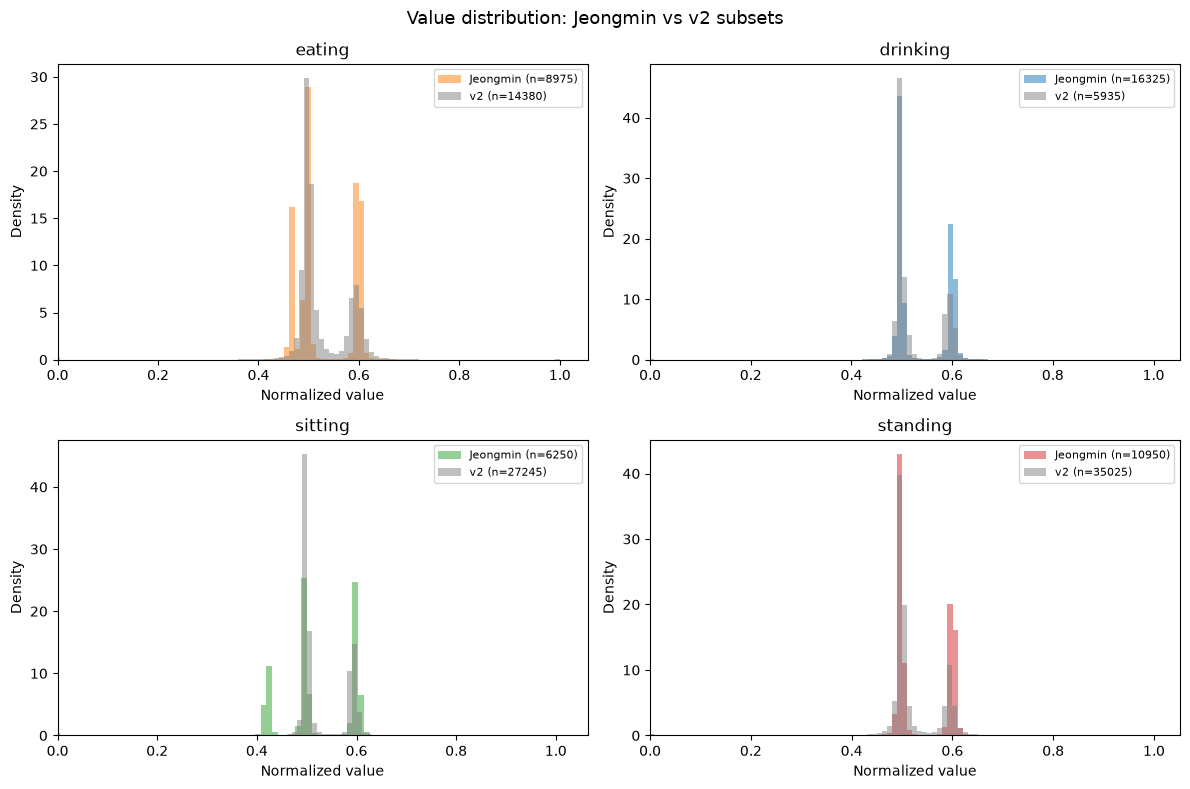

                             --- Jeongmin ---                 --- v2 subsets ---
Activity        rows    mean     std     min     max      rows    mean     std     min     max
--------------------------------------------------------------------------------
eating          8975  0.5300  0.0637 -0.0582  1.0021     14380  0.5252  0.0484  0.0000  1.0000
drinking       16325  0.5370  0.0571 -0.0015  1.0024      5935  0.5237  0.0442  0.0017  1.0000
sitting         6250  0.5204  0.0773 -0.1448  1.0060     27245  0.5275  0.0473  0.0000  1.0000
standing       10950  0.5367  0.0587 -0.0017  1.0015     35025  0.5219  0.0483  0.0000  1.0000


In [13]:
# ── v2 subsets vs Jeongmin's data: direct comparison ─────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ACTIVITIES = ["eating", "drinking", "sitting", "standing"]
COLORS = {"eating": "tab:orange", "drinking": "tab:blue",
          "sitting": "tab:green",  "standing": "tab:red"}
rng = np.random.default_rng(0)

jeongmin = {a: pd.read_csv(f"jeongmin_data/{a}_1000.csv", header=None).values
            for a in ACTIVITIES}
v2       = {a: pd.read_csv(Path("v2_data/subsets") / f"{a}_1000.csv", header=None).values
            for a in ACTIVITIES}

# ── Mean ± std envelope comparison ───────────────────────────────────────────
fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(16, 12), sharex=True)
fig.suptitle("Mean ± 1 std envelope: Jeongmin (left) vs v2 subsets (right)", fontsize=13)

for row, act in enumerate(ACTIVITIES):
    color = COLORS[act]
    t = np.arange(1000)
    for col, (data, label) in enumerate([(jeongmin[act], "Jeongmin"), (v2[act], "v2")]):
        ax = axes[row, col]
        mean, std = data.mean(axis=0), data.std(axis=0)
        ax.fill_between(t, mean - std, mean + std, alpha=0.2, color=color)
        ax.plot(t, mean, color=color, lw=1.8, label=f"{label} mean (n={len(data)})")
        idx = rng.choice(len(data), size=5, replace=False)
        for i, r in enumerate(data[idx]):
            ax.plot(t, r, color=color, alpha=0.3, lw=0.6,
                    label="samples" if i == 0 else None)
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.set_ylabel(act if col == 0 else "")
        ax.legend(loc="upper right", fontsize=7)
        if row == 0:
            ax.set_title(label, fontsize=11)

for ax in axes[-1]:
    ax.set_xlabel("Time sample (within 1000-pt window)")
plt.tight_layout()
plt.show()

# ── Value distribution overlay per class ─────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Value distribution: Jeongmin vs v2 subsets", fontsize=13)

for ax, act in zip(axes.ravel(), ACTIVITIES):
    ax.hist(jeongmin[act].ravel(), bins=100, alpha=0.5, color=COLORS[act],
            density=True, label=f"Jeongmin (n={len(jeongmin[act])})")
    ax.hist(v2[act].ravel(), bins=100, alpha=0.5, color="gray",
            density=True, label=f"v2 (n={len(v2[act])})")
    ax.set_title(act)
    ax.set_xlabel("Normalized value")
    ax.set_ylabel("Density")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── Summary stats comparison ──────────────────────────────────────────────────
print(f"{'':12} {'--- Jeongmin ---':>32}   {'--- v2 subsets ---':>32}")
print(f"{'Activity':<12} {'rows':>7} {'mean':>7} {'std':>7} {'min':>7} {'max':>7}   "
      f"{'rows':>7} {'mean':>7} {'std':>7} {'min':>7} {'max':>7}")
print("-" * 80)
for act in ACTIVITIES:
    j, v = jeongmin[act], v2[act]
    print(f"{act:<12} {j.shape[0]:>7} {j.mean():>7.4f} {j.std():>7.4f} "
          f"{j.min():>7.4f} {j.max():>7.4f}   "
          f"{v.shape[0]:>7} {v.mean():>7.4f} {v.std():>7.4f} "
          f"{v.min():>7.4f} {v.max():>7.4f}")
